# Homework 3 Solution

## Question 1: Solving a likelihood equation

### Part 1

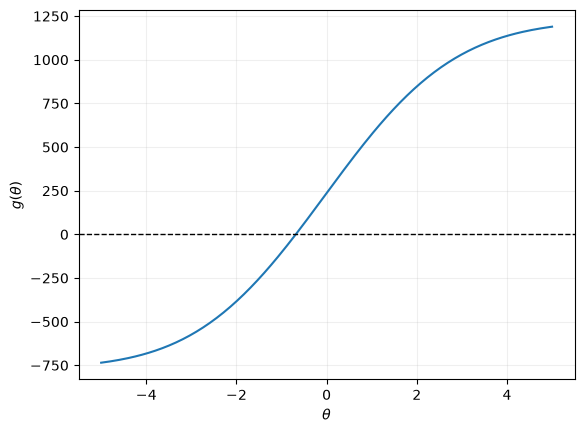

g(-5) = -735.106, g(5) = 1189.485


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.optimize import minimize

rng = np.random.default_rng(123)
n = 2000
offset = rng.normal(scale=1.5, size=n)
theta_true = -0.7
y = rng.binomial(1, expit(theta_true + offset))

def g(theta):
    return np.sum(expit(theta + offset) - y)

def g_prime(theta):
    p = expit(theta + offset)
    return np.sum(p * (1 - p))

grid = np.linspace(-5, 5, 200)
plt.plot(grid, [g(theta) for theta in grid])
plt.axhline(0, color="black", linewidth=1, linestyle="dashed")
plt.xlabel(r"$\theta$"); plt.ylabel(r"$g(\theta)$")
plt.grid(alpha=0.2)
plt.show()
print(f"g(-5) = {g(-5):.3f}, g(5) = {g(5):.3f}")


The endpoint values have opposite signs, so continuity guarantees at least one root in $[-5,5]$. Because $g'(\theta)>0$ for finite $\theta$, $g$ is strictly increasing and the root is unique.

### Part 2

In [2]:
left, right = -5.0, 5.0
for iteration in range(1, 101):
    theta = (left + right) / 2
    if abs(g(theta)) < 1e-8 or right - left < 1e-8:
        break
    if g(left) * g(theta) <= 0:
        right = theta
    else:
        left = theta
print(f"Root: {theta:.10f}; residual: {g(theta):.3e}")
print(f"Iterations: {iteration}; bracket width: {right - left:.3e}")


Root: -0.6835231511; residual: 7.294e-07
Iterations: 31; bracket width: 9.313e-09


Bisection converges to $\widehat\theta\approx-0.683523$. The sign-changing bracket guarantees convergence, but the interval shrinks by only a factor of two per iteration.

### Part 3

In [3]:
def newton(start):
    theta, path, status = start, [start], "maximum iterations"
    for _ in range(20):
        if abs(g(theta)) < 1e-8:
            status = "converged"; break
        derivative = g_prime(theta)
        if derivative < 1e-12 or not np.isfinite(theta):
            status = "failed"; break
        theta -= g(theta) / derivative
        path.append(theta)
    return theta, np.array(path), status

for start in [0.0, 3.0]:
    root, path, status = newton(start)
    print(f"start={start}: {status}; iterates={np.round(path, 6)}")


start=0.0: converged; iterates=[ 0.       -0.674209 -0.683517 -0.683523]
start=3.0: failed; iterates=[   3.         -4.309974    7.470236 -333.886611]


Starting at zero, Newton reaches the root in three updates because the local linear approximations become very accurate near the solution. Starting at three, the first steps leave the useful region and eventually encounter an almost-zero derivative, producing an enormous step. Newton is fast locally but has no global guarantee; bisection is slower but remains inside its valid bracket.

## Question 2: Step size and curvature in optimization

### Part 1

In [4]:
angle = np.pi / 6
R = np.array([[np.cos(angle), -np.sin(angle)],
              [np.sin(angle),  np.cos(angle)]])
A = R @ np.diag([1.0, 100.0]) @ R.T
b = np.array([1.0, -1.0])
x0 = np.array([3.0, -2.0])
objective = lambda x: 0.5 * x @ A @ x - b @ x
gradient = lambda x: A @ x - b

eigenvalues = np.linalg.eigvalsh(A)
x_star = np.linalg.solve(A, b)
print("Eigenvalues:", eigenvalues, "Condition number:", eigenvalues[-1] / eigenvalues[0])
print("Exact minimizer:", x_star, "Convergent step-size interval: (0,", 2 / eigenvalues[-1], ")")


Eigenvalues: [  1. 100.] Condition number: 100.00000000000028
Exact minimizer: [0.32381743 0.17118257] Convergent step-size interval: (0, 0.02 )


The eigenvalues are 1 and 100, so $\kappa_2(A)=100$ and fixed-step gradient descent requires $0<\alpha<0.02$. The unequal eigenvalues create a narrow valley and slow progress in the low-curvature direction.

### Part 2

step=0.005: gap=2.785e-01, gradient norm=7.463e-01
step=0.015: gap=3.694e-02, gradient norm=2.718e-01
step=0.021: gap=9.835e+10, gradient norm=4.435e+06


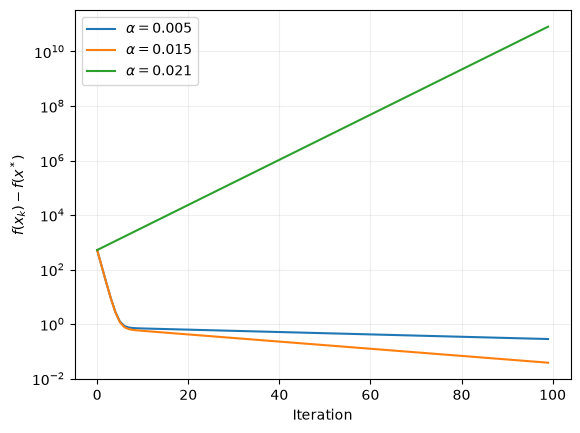

In [5]:
histories = {}
for step in [0.005, 0.015, 0.021]:
    x, gaps = x0.copy(), []
    for _ in range(100):
        gaps.append(objective(x) - objective(x_star))
        x -= step * gradient(x)
    histories[step] = gaps
    print(f"step={step}: gap={objective(x)-objective(x_star):.3e}, "
          f"gradient norm={np.linalg.norm(gradient(x)):.3e}")
for step, gaps in histories.items():
    plt.semilogy(gaps, label=fr"$\alpha={step}$")
plt.xlabel("Iteration"); plt.ylabel(r"$f(x_k)-f(x^*)$")
plt.legend(); plt.grid(alpha=0.2); plt.show()


The two step sizes below 0.02 converge, with $\alpha=0.015$ making faster progress in the low-curvature direction. For $\alpha=0.021$, the multiplier in the largest-eigenvalue direction is $1-0.021(100)=-1.1$, whose magnitude exceeds one, so the iterates oscillate and diverge.

### Part 3

In [6]:
x, evaluations = x0.copy(), 0
for iterations in range(2001):
    grad = gradient(x)
    if np.linalg.norm(grad) < 1e-6 or iterations == 2000:
        break
    step, current = 1.0, objective(x)
    evaluations += 1
    while True:
        trial = objective(x - step * grad); evaluations += 1
        if trial <= current - 1e-4 * step * grad @ grad:
            break
        step *= 0.5
    x -= step * grad
print("Final point:", x)
print(f"Gap: {objective(x)-objective(x_star):.3e}; gradient norm: {np.linalg.norm(gradient(x)):.3e}")
print(f"Iterations: {iterations}; objective evaluations: {evaluations}")


Final point: [0.32381803 0.17118293]
Gap: 2.461e-13; gradient norm: 8.796e-07
Iterations: 645; objective evaluations: 4896


Backtracking automatically finds acceptable step sizes and converges without knowing $\lambda_{\max}(A)$. It is reliable here, although the ill-conditioned valley still makes first-order progress slow.

## Question 3: Mini-batch logistic regression

The four methods use the same starting point and the same budget of 50 passes through the training data. The three stochastic methods also use the same pre-generated mini-batches.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from time import perf_counter

rng = np.random.default_rng(789)
n_train, n_valid, p = 8000, 2000, 20
X = rng.normal(size=(n_train + n_valid, p))
beta_true = rng.normal(scale=0.35, size=p)
y = rng.binomial(1, expit(X @ beta_true))
X_train, X_valid = X[:n_train], X[n_train:]
y_train, y_valid = y[:n_train], y[n_train:]
lam = 1e-3

def data_loss(beta, X, y):
    eta = X @ beta
    return np.mean(np.logaddexp(0, eta) - y * eta)

def train_objective(beta):
    return data_loss(beta, X_train, y_train) + 0.5 * lam * (beta @ beta)

def batch_gradient(beta, X, y):
    return X.T @ (expit(X @ beta) - y) / len(y) + lam * beta

batch_size, epochs = 64, 50
steps = epochs * n_train // batch_size
batch_rng = np.random.default_rng(2468)
batch_indices = batch_rng.integers(0, n_train, size=(steps, batch_size))


### Part 1

The history stores processed observations, training objective, validation loss, and elapsed time after each equivalent pass through the training data.


In [8]:
def record(beta, processed, start):
    return [processed, train_objective(beta),
            data_loss(beta, X_valid, y_valid), perf_counter() - start]

def full_batch():
    beta, history, start = np.zeros(p), [], perf_counter()
    history.append(record(beta, 0, start))
    for epoch in range(epochs):
        beta -= batch_gradient(beta, X_train, y_train)
        history.append(record(beta, (epoch + 1) * n_train, start))
    return beta, np.array(history)

def stochastic(method):
    beta = np.zeros(p); m = np.zeros(p); v = np.zeros(p)
    history, start = [], perf_counter()
    history.append(record(beta, 0, start))
    for t, ind in enumerate(batch_indices, 1):
        g = batch_gradient(beta, X_train[ind], y_train[ind])
        if method == "SGD":
            beta -= 0.05 * g
        elif method == "Momentum":
            m = 0.9 * m + 0.1 * g
            beta -= 0.05 * m
        else:
            m = 0.9 * m + 0.1 * g
            v = 0.999 * v + 0.001 * g**2
            beta -= 0.002 * (m / (1 - 0.9**t)) / (np.sqrt(v / (1 - 0.999**t)) + 1e-8)
        if t % (n_train // batch_size) == 0:
            history.append(record(beta, t * batch_size, start))
    return beta, np.array(history)

runs = {"Full-batch GD": full_batch(),
        "Mini-batch SGD": stochastic("SGD")}


### Part 2

Momentum uses the update specified in the question. Adam uses bias-corrected first and second moments.


Method                Train      Valid    Seconds
Full-batch GD      0.511600   0.511607      0.012
Mini-batch SGD     0.512202   0.511885      0.043
Momentum           0.512216   0.511798      0.048
Adam               0.512029   0.511579      0.061


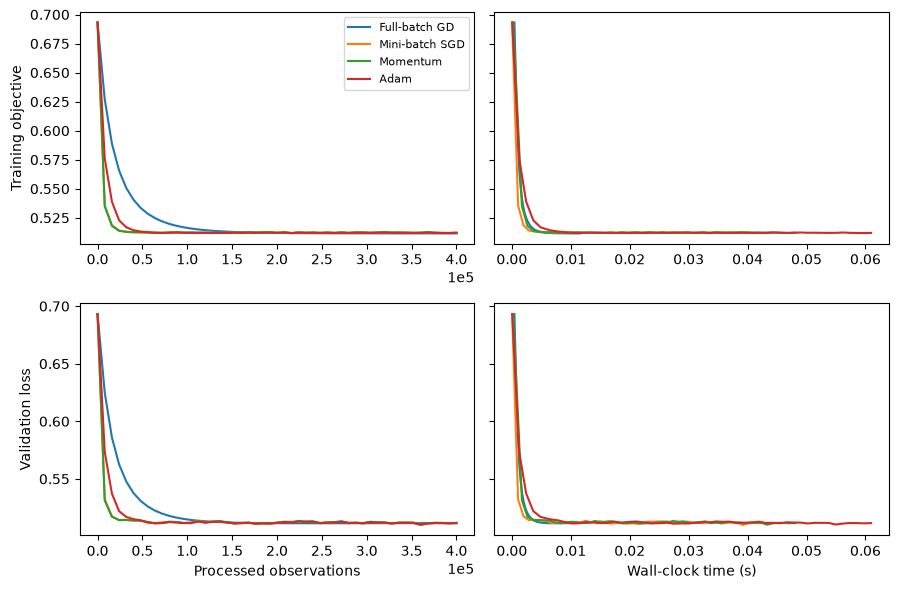

In [9]:
runs["Momentum"] = stochastic("Momentum")
runs["Adam"] = stochastic("Adam")

print(f"{'Method':<16} {'Train':>10} {'Valid':>10} {'Seconds':>10}")
for name, (_, h) in runs.items():
    print(f"{name:<16} {h[-1,1]:10.6f} {h[-1,2]:10.6f} {h[-1,3]:10.3f}")

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey='row')
for name, (_, h) in runs.items():
    axes[0,0].plot(h[:,0], h[:,1], label=name)
    axes[1,0].plot(h[:,0], h[:,2])
    axes[0,1].plot(h[:,3], h[:,1])
    axes[1,1].plot(h[:,3], h[:,2])
axes[0,0].set_ylabel("Training objective"); axes[1,0].set_ylabel("Validation loss")
axes[1,0].set_xlabel("Processed observations"); axes[1,1].set_xlabel("Wall-clock time (s)")
for ax in axes[:,0]: ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0,0].legend(fontsize=8); fig.tight_layout(); plt.show()


All four methods reach similar objective values with these settings. Full-batch gradient descent is especially competitive in wall-clock time for this small dense problem because each update uses efficient matrix operations. The stochastic paths fluctuate more because each update uses only 64 observations; momentum smooths those updates, while Adam adapts the step size coordinate by coordinate. Timing values are machine-dependent.
